<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_IntrusionDetection_Kerkatou2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lightweight hybrid quantum neural network for binary intrusion detection: Kerkatou et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Raid Anis Kerkatou, Hacene Belhadef, Aicha Eutamene and Svetlana Petrova Stefanova, "A Lightweight Hybrid Quantum Neural
> Network for Binary Intrusion Detection", *2026 International Conference on Computer Systems and Technologies
> (CompSysTech)*, IEEE, 2026. DOI 10.1109/COMPSYSTECH69798.2026.11683102

The paper publishes no code. Everything below is written from its six-page description with the software stack the paper
names: **PennyLane** for the quantum circuit, **PyTorch** for the hybrid training loop (Adam, binary cross-entropy) and
scikit-learn for preprocessing, PCA and the classical baselines.

**What the notebook does.** It downloads the 20 % subset of NSL-KDD, applies the paper's preprocessing (one-hot encoding,
scaling to a bounded range, class balancing, PCA fitted on the training split only), encodes each PCA-reduced connection
into a small quantum circuit with one of the paper's three embeddings (**angle** with 6 principal components, **amplitude**
with 8, **IQP** with 6), adds a trainable variational block, reads out a Pauli-Z expectation value, turns it into an
attack probability with a sigmoid and trains the whole thing with Adam on binary cross-entropy. SVM (RBF), Random Forest,
Logistic Regression and a small MLP are trained on the very same inputs. The paper's figures (PCA variance, convergence,
confusion matrices, embedding comparison) are redrawn and the last section puts the paper's Table I next to the numbers
obtained here, with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
a pinned PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and
no Hugging Face token are needed: NSL-KDD is a small public file on GitHub (nothing here is gated).

**Runtime.** RUNTIME TBD

**What you get at the end.** Accuracy, precision, recall, F1 and confusion matrices of three hybrid QNNs and four classical
models, the circuit diagrams that were actually executed, learning curves, an ablation over PCA size and circuit depth, and
a claim-by-claim comparison with the paper.

## The paper in one page

**Problem.** Decide for each network connection whether it is normal traffic or an attack (binary intrusion detection),
with a model that is small enough for near-term (NISQ) quantum hardware.

**Decision.** A hybrid quantum neural network (H-QNN): classical preprocessing, a quantum circuit that embeds the features,
a variational block with trainable rotations and entangling gates, a Pauli expectation value as output, a classical
activation, and gradient-based training in a quantum-classical loop (PennyLane + PyTorch, parameter-shift gradients).

**Data.** "A subset (20 %) of the NSL-KDD dataset", 41 features, normal vs attack (Sec. IV.A). One-hot encoding of the
categorical features, normalisation to a bounded range, class balancing by sampling, a stratified train/test split.

**Method.** PCA to 6 or 8 components (one per qubit for angle / IQP embedding; amplitude embedding packs 8 values into
3 qubits) -> embedding (Angle `RY(z_i)`, Amplitude, IQP) -> variational layers -> `<Z>` -> activation -> BCE loss, Adam.

**Claims (Table I, NSL-KDD binary).**

| Model | Embedding | PCA | Accuracy | F1 | Training time (s) |
|---|---|---|---|---|---|
| H-QNN | Angle | 6 | 0.9845 | 0.9830 | 3010.12 |
| H-QNN | Amplitude | 8 | **0.9881** | **0.9875** | 4620.45 |
| H-QNN | IQP | 6 | 0.9572 | 0.9550 | 4605.77 |
| SVM (RBF) | - | - | 0.963 | 0.961 | 15.2 |
| Random Forest | - | - | 0.972 | 0.970 | 14.8 |
| Logistic Regression | - | - | 0.948 | 0.945 | 3.2 |

Further claims in the text: the amplitude H-QNN is the best model overall; it has a *lower false-negative rate* than the
Random Forest (Fig. 4); the amplitude model (PCA = 8, 2 variational layers) has "approximately 64" trainable parameters
against "several thousand" for a comparable MLP; IQP "underperforms"; angle embedding trains with shallower circuits and
less time than amplitude embedding; training is much slower than the classical baselines.

### What follows the paper and what had to be chosen

The paper is a short conference paper and leaves many details open. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data file | "20 % subset of NSL-KDD" | `KDDTrain+_20Percent.txt` (25,192 connections) from a public GitHub mirror; we assume this is the paper's subset |
| Cleaning | "removal of inconsistent or corrupted records" | exact duplicates dropped (none found), columns that are constant in the training split dropped |
| Categorical features | one-hot encoding | `OneHotEncoder` fitted on the training split (protocol, service, flag) -> about 115 columns |
| Normalisation | "scaled to a bounded range" | `MinMaxScaler` to [0, 1] fitted on the training split, test values clipped |
| Class balancing | "sampling techniques" | random under-sampling of the majority class to the size of the minority class (11,743 per class) |
| Split | stratified train/test, ratio not given | 80 : 20 stratified; repeated for 3 seeds (a new balanced draw and split per seed) |
| PCA | 6 or 8 components, fitted on ? | PCA fitted on the training split only (`svd_solver="full"`) |
| Angle embedding | `RY(z_i)` | `AngleEmbedding(rotation="Y")` on the PCA scores mapped to [0, pi] (min-max fitted on the training split) |
| Amplitude embedding | normalised feature vector | `AmplitudeEmbedding(normalize=True)` on the 8 raw PCA scores -> 3 qubits |
| IQP embedding | "entangling layers" | `IQPEmbedding(n_repeats=2)` on the same angles as the angle embedding, 6 qubits |
| Variational block | "multiple parameterised rotation layers + entanglement"; amplitude model: 2 layers, "about 64" parameters | `StronglyEntanglingLayers`, 2 layers for every embedding (3 qubits x 2 layers x 3 = 18 parameters for amplitude); depth ablation up to 7 layers (63 parameters) |
| Output | Pauli expectation value -> "classical activation" | `<Z_0>` -> `sigmoid(a <Z_0> + b)` with trainable scalars `a`, `b` (2 extra parameters) |
| Optimiser | Adam, fixed learning rate, "multiple epochs until convergence" | Adam, learning rate 0.05, batch 128, fixed epoch budget (see configuration) |
| Gradients | parameter-shift rule | exact back-propagation through the PennyLane simulator (same gradient, much faster); the equality with the parameter-shift rule is checked in the circuit section |
| Baselines | SVM (RBF), Random Forest, Logistic Regression; "identical preprocessing and PCA settings"; hyper-parameters not given | scikit-learn defaults on the same PCA inputs (6 and 8 components) and, in addition, on all features; plus a small MLP for the parameter-count claim |
| Metrics | accuracy, F1, confusion matrix | the same, attack = positive class; F1 is for the attack class |
| Hardware | i7 CPU, 32 GB, simulator | shared laptop CPU, PennyLane `default.qubit` simulator |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): pennylane 0.45.1, torch 2.14 (CPU). Colab already ships torch, numpy,
# pandas, scikit-learn and matplotlib. The pip line runs on Colab (or wherever PennyLane / PyTorch are missing); a prepared
# local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("torch") is None:
    %pip install -q "pennylane==0.45.1" torch
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and torch already present; skipping pip install.")

pennylane and torch already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in a few minutes. False: the full run described in the "Runtime" paragraph.
SEED      = 42              # CHOICE: the paper does not give a seed
IBM_TOKEN = ""              # not used (the paper simulates; no hardware run)

if FAST_MODE:
    N_PER_CLASS = 1000      # CHOICE: balanced connections per class (2,000 in total)
    EPOCHS      = 8
    SEEDS       = [42]
    ABLATION_PCA    = {"angle": [], "amplitude": [4, 16], "iqp": []}
    ABLATION_LAYERS = [1, 4, 7]       # amplitude embedding, PCA = 8
else:
    N_PER_CLASS = None      # None: all of the minority class (11,743 per class, 23,486 connections)
    EPOCHS      = 10
    SEEDS       = [42, 43, 44]
    ABLATION_PCA    = {"angle": [4], "amplitude": [4, 16], "iqp": []}
    ABLATION_LAYERS = [1, 4, 7]

MAIN_MODELS = [("angle", 6), ("amplitude", 8), ("iqp", 6)]   # paper, Table I: (embedding, PCA components)
LAYERS      = 2             # variational layers (paper: 2 for the amplitude model; CHOICE: the same for all)
BATCH       = 128           # CHOICE: mini-batch size
LR          = 0.05          # CHOICE: Adam learning rate ("fixed learning rate" in the paper)
TEST_SIZE   = 0.20          # CHOICE: the paper only says "stratified split"
MAX_K       = 16            # PCA is fitted once with 16 components; the first k columns are the k-component PCA
PROBE       = 1000          # training rows on which the accuracy is tracked after every epoch (learning curve)
PRINT_EVERY = 3

DATA_DIR  = "data"
DATA_FILE = "KDDTrain+_20Percent.txt"
DATA_URLS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B_20Percent.txt",
             "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B_20Percent.txt"]

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import torch
import pennylane as qml

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| epochs:", EPOCHS, "| balanced connections per class:", N_PER_CLASS or "all")

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | seeds: [42, 43, 44] | epochs: 10 | balanced connections per class: all


## 1. The NSL-KDD data (20 % subset)

NSL-KDD (Tavallaee et al., 2009) is the cleaned-up version of the KDD Cup 1999 data: every row is one TCP/UDP/ICMP connection
described by 41 features (duration, protocol, service, bytes in each direction, login flags, error rates over the last 100
connections, ...), a label that names the attack type or `normal`, and a difficulty score that we ignore. The paper uses "a
subset (20 %) of the NSL-KDD dataset"; the NSL-KDD authors publish exactly such a file, `KDDTrain+_20Percent.txt`
(25,192 connections), so that is what we download (3.8 MB, cached in `DATA_DIR`).

The paper's task is binary: **normal vs attack**. We also keep the attack type and map it to the four standard NSL-KDD
families (DoS, Probe, R2L, U2R) so that the plots later can show the original, multiclass structure of the data.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
NUM_COLS = [c for c in COLUMNS if c not in CAT_COLS + ["label", "difficulty"]]

FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    FAMILY[a] = "U2R"
FAMILIES = ["normal", "DoS", "Probe", "R2L", "U2R"]
FAM_COLOUR = {"normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple"}

def fetch_data():
    path = os.path.join(DATA_DIR, DATA_FILE)
    if not os.path.exists(path):
        import requests
        for url in DATA_URLS:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", DATA_FILE, "from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + DATA_FILE + "; put the file into DATA_DIR by hand")
    else:
        print("using cached", path)
    return pd.read_csv(path, header=None, names=COLUMNS)

raw = fetch_data()
n_before = len(raw)
raw = raw.drop(columns="difficulty").drop_duplicates().reset_index(drop=True)       # paper: remove corrupted / redundant records
raw["family"] = raw["label"].map(FAMILY)
assert raw["family"].notna().all(), "unmapped attack names: %s" % sorted(raw.loc[raw["family"].isna(), "label"].unique())
raw["binary"] = (raw["label"] != "normal").astype(int)                              # 1 = attack (positive class), 0 = normal
print("rows read:", n_before, "| after dropping exact duplicates:", len(raw))
print("normal:", int((raw.binary == 0).sum()), "| attack:", int((raw.binary == 1).sum()))

using cached data\KDDTrain+_20Percent.txt


rows read: 25192 | after dropping exact duplicates: 25192
normal: 13449 | attack: 11743


## 2. Balanced sample, train/test split and preprocessing

The paper balances the classes "using sampling techniques" and then evaluates on "unseen test data" from a stratified
split. For each seed we (1) under-sample the majority class (normal) to the size of the minority class, (2) split 80 : 20
with stratification, and (3) fit every transform **on the training part only**:

1. one-hot encoding of `protocol_type`, `service`, `flag` (categories seen in training; an unseen category becomes all zeros),
2. dropping columns that are constant in the training split,
3. min-max scaling of all columns to [0, 1] (the paper's "bounded range"; test values are clipped to [0, 1]),
4. PCA to `MAX_K = 16` components. Because principal components are nested, the first *k* columns are exactly a *k*-component
   PCA, so one fit serves the 6- and 8-component models and the PCA ablation.

Then each embedding gets its own view of the PCA scores. **Angle** and **IQP** embeddings need rotation angles, so every
component is mapped to [0, pi] with a min-max scaler fitted on the training split (test values clipped). **Amplitude**
embedding takes the raw PCA scores and normalises each 8-vector to unit length inside the circuit. The classical baselines
receive exactly the same numbers as the corresponding quantum model.

In [5]:
def balanced_sample(seed):
    # CHOICE: random under-sampling of the majority class (normal) to the size of the minority class (or N_PER_CLASS)
    n_min = int(raw["binary"].value_counts().min())
    n = n_min if N_PER_CLASS is None else min(N_PER_CLASS, n_min)
    parts = [raw[raw["binary"] == c].sample(n=n, random_state=seed) for c in (0, 1)]
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

def prepare(seed):
    """Balanced draw -> stratified split -> one-hot -> constant-column drop -> min-max -> PCA. Everything fitted on train only."""
    bal = balanced_sample(seed)
    idx_tr, idx_te = train_test_split(np.arange(len(bal)), test_size=TEST_SIZE, stratify=bal["binary"], random_state=seed)
    tr, te = bal.iloc[idx_tr].reset_index(drop=True), bal.iloc[idx_te].reset_index(drop=True)
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(tr[CAT_COLS])
    names = NUM_COLS + list(enc.get_feature_names_out(CAT_COLS))
    design = lambda d: np.hstack([d[NUM_COLS].to_numpy(float), enc.transform(d[CAT_COLS])])
    Xtr, Xte = design(tr), design(te)
    keep = Xtr.std(axis=0) > 0                                                   # drop constant columns (training split)
    Xtr, Xte, names = Xtr[:, keep], Xte[:, keep], [n for n, k in zip(names, keep) if k]
    mm = MinMaxScaler().fit(Xtr)                                                 # CHOICE: [0, 1], test clipped
    Ztr, Zte = mm.transform(Xtr), np.clip(mm.transform(Xte), 0.0, 1.0)
    pca = PCA(n_components=MAX_K, svd_solver="full", random_state=seed).fit(Ztr)
    return dict(seed=seed, tr=tr, te=te, names=names, Ztr=Ztr, Zte=Zte, pca=pca,
                Ptr=pca.transform(Ztr), Pte=pca.transform(Zte),
                ytr=tr["binary"].to_numpy(), yte=te["binary"].to_numpy())

def q_inputs(d, emb, k):
    """The k numbers per connection that the quantum model (and its classical twins) receive."""
    Ptr, Pte = d["Ptr"][:, :k], d["Pte"][:, :k]
    if emb == "amplitude":                       # raw PCA scores; the circuit normalises them to unit length
        return Ptr, Pte
    sc = MinMaxScaler((0.0, np.pi)).fit(Ptr)     # CHOICE: angles in [0, pi], fitted on training scores, test clipped
    return sc.transform(Ptr), np.clip(sc.transform(Pte), 0.0, np.pi)

t0 = time.time()
DATA = {s: prepare(s) for s in SEEDS}
for s, d in DATA.items():
    print(f"seed {s}: train {d['Ztr'].shape} (attack share {d['ytr'].mean():.2f}) | test {d['Zte'].shape} (attack share {d['yte'].mean():.2f}) "
          f"| PCA keeps {d['pca'].explained_variance_ratio_[:6].sum():.1%} (6 comps), {d['pca'].explained_variance_ratio_[:8].sum():.1%} (8 comps)")
amp_norm = min(np.linalg.norm(d["Ptr"][:, :8], axis=1).min() for d in DATA.values())
print("smallest norm of an 8-component PCA vector (amplitude embedding needs > 0): %.2e" % amp_norm)
print("prepared in %.1f s" % (time.time() - t0))

seed 42: train (18788, 116) (attack share 0.50) | test (4698, 116) (attack share 0.50) | PCA keeps 79.9% (6 comps), 84.0% (8 comps)
seed 43: train (18788, 115) (attack share 0.50) | test (4698, 115) (attack share 0.50) | PCA keeps 79.7% (6 comps), 83.8% (8 comps)
seed 44: train (18788, 116) (attack share 0.50) | test (4698, 116) (attack share 0.50) | PCA keeps 79.9% (6 comps), 84.0% (8 comps)
smallest norm of an 8-component PCA vector (amplitude embedding needs > 0): 6.02e-01
prepared in 4.3 s


## Dataset Exploration and Visualisation

All plots below show **real** NSL-KDD connections, coloured by their ground-truth label. First the raw file (shape, feature
names, original label values and counts, class distributions), then the balanced training split of the first seed after the
preprocessing: the scatter plots use the first two principal components, first as raw PCA coordinates (PCA fitted on the training split) and then as
the angles in [0, pi] that the angle and IQP embeddings receive. Colours show the attack *family*, not only the binary label.
The last figure redraws the paper's Fig. 3 (explained variance).

In [6]:
D0 = DATA[SEEDS[0]]
print("raw dataset shape (after removing duplicates):", raw.shape, "(columns: 41 features + label + family + binary)")
print("\n41 original features:")
print("  numeric    (%d):" % len(NUM_COLS), ", ".join(NUM_COLS))
print("  categorical (3):", ", ".join(f"{c} ({raw[c].nunique()} values)" for c in CAT_COLS))
print("\nfeature columns after one-hot + constant-column removal (seed %d): %d" % (D0["seed"], len(D0["names"])))
print("  first 12:", D0["names"][:12], "...")
print("\noriginal label values and counts (%d distinct):" % raw["label"].nunique())
lab = raw.groupby(["family", "label"]).size().reset_index(name="count").sort_values(["family", "count"], ascending=[True, False])
print(lab.to_string(index=False))
print("\nbinary labels: normal =", int((raw.binary == 0).sum()), "| attack =", int((raw.binary == 1).sum()))
print("attack families:", raw["family"].value_counts().to_dict())

raw dataset shape (after removing duplicates): (25192, 44) (columns: 41 features + label + family + binary)

41 original features:
  numeric    (38): duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
  categorical (3): protocol_type (3 values), service (66 values), flag (11 values)

feature columns after one-hot + constant-column removal (seed 42): 116
  first 12: ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'ur

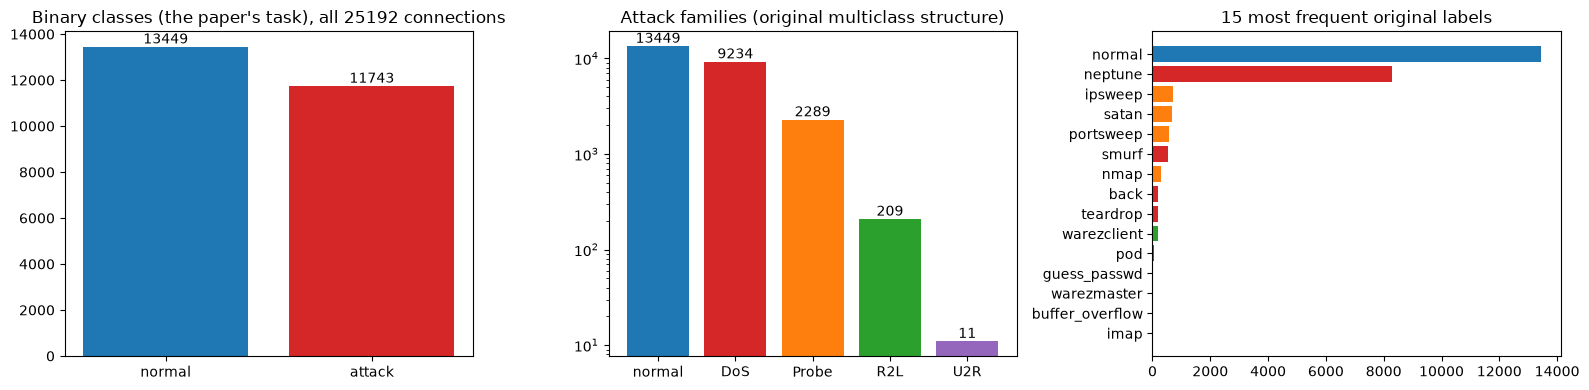

balanced split, seed 42 - connections per attack family:


family,normal,DoS,Probe,R2L,U2R
train,9394,7378,1847,161,8
test,2349,1856,442,48,3


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
vc = raw["binary"].map({0: "normal", 1: "attack"}).value_counts().reindex(["normal", "attack"])
axes[0].bar(vc.index, vc.values, color=["tab:blue", "tab:red"]); axes[0].set_title("Binary classes (the paper's task), all %d connections" % len(raw))
for i, v in enumerate(vc.values): axes[0].text(i, v, str(v), ha="center", va="bottom")
fc = raw["family"].value_counts().reindex(FAMILIES)
axes[1].bar(fc.index, fc.values, color=[FAM_COLOUR[f] for f in fc.index]); axes[1].set_title("Attack families (original multiclass structure)")
axes[1].set_yscale("log")
for i, v in enumerate(fc.values): axes[1].text(i, v, str(v), ha="center", va="bottom")
top = raw["label"].value_counts().head(15)[::-1]
axes[2].barh(top.index, top.values, color=[FAM_COLOUR[FAMILY[n]] for n in top.index]); axes[2].set_title("15 most frequent original labels")
plt.tight_layout(); plt.show()

# class distribution of the balanced training / test split actually used (seed %d)
tab = pd.DataFrame({"train": D0["tr"]["family"].value_counts(), "test": D0["te"]["family"].value_counts()}).reindex(FAMILIES).fillna(0).astype(int)
print("balanced split, seed", D0["seed"], "- connections per attack family:"); display(tab.T)

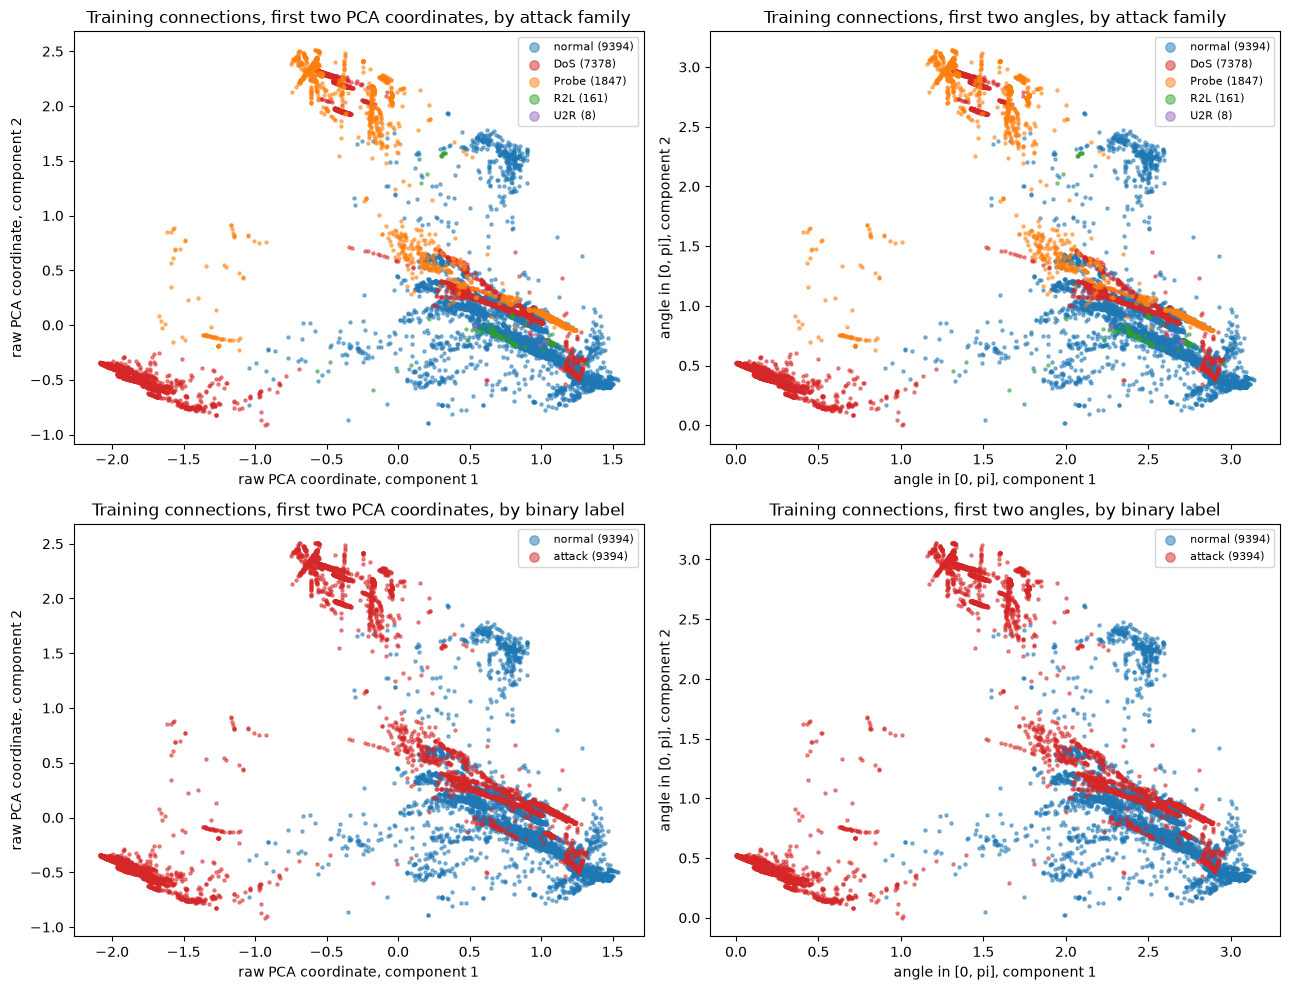

Every point is one real training connection (18788 in total); the classes overlap strongly in two dimensions, which is why the models use 6-8 components.


In [8]:
d = D0
P6 = d["Ptr"][:, :2]
A6 = q_inputs(d, "angle", 6)[0][:, :2]
fam_tr = d["tr"]["family"].to_numpy(); bin_tr = d["ytr"]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (labels, order, colours, title) in enumerate([(fam_tr, FAMILIES, FAM_COLOUR, "attack family"),
                                                        (np.where(bin_tr == 1, "attack", "normal"), ["normal", "attack"],
                                                         {"normal": "tab:blue", "attack": "tab:red"}, "binary label")]):
    for col, (xy, xl) in enumerate([(P6, "raw PCA coordinate"), (A6, "angle in [0, pi]")]):
        ax = axes[row, col]
        for c in order:
            m = labels == c
            ax.scatter(xy[m, 0], xy[m, 1], s=5, alpha=0.5, c=colours[c], label=f"{c} ({m.sum()})")
        ax.set_xlabel(f"{xl}, component 1"); ax.set_ylabel(f"{xl}, component 2")
        ax.set_title(f"Training connections, first two {'PCA coordinates' if col == 0 else 'angles'}, by {title}")
        ax.legend(fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()
print("Every point is one real training connection (%d in total); the classes overlap strongly in two dimensions, which is why "
      "the models use 6-8 components." % len(fam_tr))

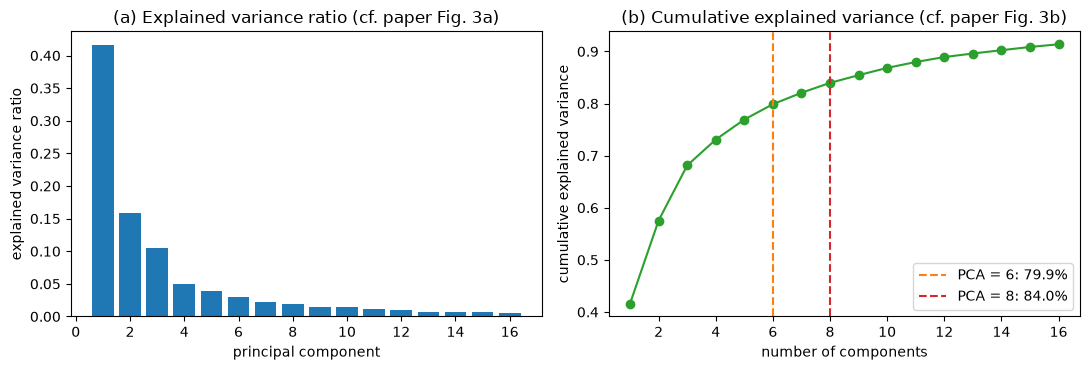

In [9]:
ev = d["pca"].explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(range(1, MAX_K + 1), ev, color="tab:blue"); axes[0].set_xlabel("principal component"); axes[0].set_ylabel("explained variance ratio")
axes[0].set_title("(a) Explained variance ratio (cf. paper Fig. 3a)")
axes[1].plot(range(1, MAX_K + 1), np.cumsum(ev), "o-", color="tab:green")
for k, c in [(6, "tab:orange"), (8, "tab:red")]:
    axes[1].axvline(k, color=c, ls="--", label=f"PCA = {k}: {ev[:k].sum():.1%}")
axes[1].set_xlabel("number of components"); axes[1].set_ylabel("cumulative explained variance"); axes[1].legend()
axes[1].set_title("(b) Cumulative explained variance (cf. paper Fig. 3b)")
plt.tight_layout(); plt.show()

## 3. Classical baselines on identical inputs

The paper compares with SVM (RBF), Random Forest and Logistic Regression "under identical preprocessing pipelines, PCA
settings and train-test splits", without hyper-parameters. We train all three with scikit-learn defaults (`SVC(kernel="rbf")`,
`RandomForestClassifier(n_estimators=100)`, `LogisticRegression(max_iter=1000)`) on **exactly the numbers the quantum model
receives**: the 6 angles (angle / IQP models), the 8 raw PCA scores (amplitude model) and, as an extra reference, all
preprocessed features. A small MLP (two hidden layers of 32 and 16 units) is added for the paper's parameter-efficiency
claim. Metrics treat *attack* as the positive class. Training + prediction time is measured with a wall clock.

In [10]:
def binary_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), fnr=fn / max(fn + tp, 1), fpr=fp / max(fp + tn, 1))

CLASSICAL = {
    "SVM (RBF)":           lambda s: SVC(kernel="rbf"),
    "Random Forest":       lambda s: RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=1),
    "Logistic Regression": lambda s: LogisticRegression(max_iter=1000, random_state=s),
    "MLP (32-16)":         lambda s: MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=s),
}

def n_params(model):
    if isinstance(model, MLPClassifier): return int(sum(c.size for c in model.coefs_) + sum(i.size for i in model.intercepts_))
    if isinstance(model, LogisticRegression): return int(model.coef_.size + model.intercept_.size)
    if isinstance(model, RandomForestClassifier): return int(sum(t.tree_.node_count for t in model.estimators_))   # tree nodes
    if isinstance(model, SVC): return int(model.support_vectors_.shape[0])                                           # support vectors
    return -1

RES = {}   # (model name, seed) -> metrics dict
PRED = {}  # (model name, seed) -> predicted labels on the test split
def run_classical(seed, inputs, tag):
    d = DATA[seed]
    Xtr, Xte = inputs
    for name, make in CLASSICAL.items():
        t0 = time.time(); m = make(seed).fit(Xtr, d["ytr"]); pred = m.predict(Xte); dt = time.time() - t0
        key = f"{name} [{tag}]"
        RES[(key, seed)] = dict(**binary_metrics(d["yte"], pred), time_s=dt, params=n_params(m))
        PRED[(key, seed)] = pred

t0 = time.time()
for s in SEEDS:
    d = DATA[s]
    run_classical(s, q_inputs(d, "angle", 6), "PCA6 angles")
    run_classical(s, q_inputs(d, "amplitude", 8), "PCA8 scores")
    run_classical(s, (d["Ztr"], d["Zte"]), "all features")
print("classical baselines done in %.1f s" % (time.time() - t0))
cl = pd.DataFrame({k: v for k, v in RES.items() if k[1] == SEEDS[0]}).T.reset_index()
cl.columns = ["model", "seed"] + list(cl.columns[2:])
print(cl[["model", "accuracy", "precision", "recall", "f1", "fnr", "fpr", "time_s", "params"]].round(4).to_string(index=False))

classical baselines done in 399.6 s
                             model  accuracy  precision  recall     f1    fnr    fpr  time_s  params
           SVM (RBF) [PCA6 angles]    0.9719     0.9890  0.9544 0.9714 0.0456 0.0106  3.7323  1374.0
       Random Forest [PCA6 angles]    0.9908     0.9932  0.9885 0.9908 0.0115 0.0068  4.0780 46724.0
 Logistic Regression [PCA6 angles]    0.9353     0.9402  0.9298 0.9349 0.0702 0.0592  0.0621     7.0
         MLP (32-16) [PCA6 angles]    0.9802     0.9804  0.9800 0.9802 0.0200 0.0196 35.6114   769.0
           SVM (RBF) [PCA8 scores]    0.9725     0.9903  0.9544 0.9720 0.0456 0.0094  3.6402  1265.0
       Random Forest [PCA8 scores]    0.9915     0.9932  0.9898 0.9915 0.0102 0.0068  5.3064 46638.0
 Logistic Regression [PCA8 scores]    0.9623     0.9673  0.9570 0.9621 0.0430 0.0324  0.0486     9.0
         MLP (32-16) [PCA8 scores]    0.9864     0.9931  0.9796 0.9863 0.0204 0.0068 38.3999   833.0
          SVM (RBF) [all features]    0.9830     0.9922

## Quantum Circuit Architecture

The hybrid model is a PennyLane `QNode` that PyTorch differentiates. All three architectures share the same skeleton,
`embedding U(x)` -> `StronglyEntanglingLayers(weights)` -> `<Z_0>`, and differ in the embedding:

| Architecture | PCA components | Qubits | Embedding | Variational block (CHOICE) |
|---|---|---|---|---|
| Angle | 6 | 6 | `AngleEmbedding(rotation="Y")`: `RY(x_i)` on qubit *i* | `StronglyEntanglingLayers`, 2 layers (a `Rot` gate on every qubit, then CNOTs at range *l*) |
| Amplitude | 8 | 3 | `AmplitudeEmbedding(normalize=True)`: the 8 values become the 8 amplitudes of 3 qubits | the same, 2 layers |
| IQP | 6 | 6 | `IQPEmbedding(n_repeats=2)`: Hadamards, `RZ(x_i)` and `ZZ(x_i x_j)` phases, repeated twice | the same, 2 layers |

The paper does not give gate-level details ("multiple parameterised rotation layers combined with entanglement gates",
Fig. 1 is generic), so the variational block is our choice. The output is `y = <Z_0>` in [-1, 1]; the classical head
`p = sigmoid(a y + b)` has two trainable scalars. The next cells build the circuits, draw the ones that are executed (once
as templates, once decomposed into the gates the simulator runs), print qubit count, depth and trainable-parameter count,
and check that the back-propagated gradient equals the parameter-shift gradient used in the paper.

In [11]:
def n_wires(emb, k):
    return int(np.ceil(np.log2(k))) if emb == "amplitude" else k

def make_qnode(emb, k, diff_method="backprop"):
    nq = n_wires(emb, k)
    dev = qml.device("default.qubit", wires=nq)
    @qml.qnode(dev, interface="torch", diff_method=diff_method)
    def circuit(x, w):
        if emb == "angle":       qml.AngleEmbedding(x, wires=range(nq), rotation="Y")
        elif emb == "iqp":       qml.IQPEmbedding(x, wires=range(nq), n_repeats=2)               # CHOICE: 2 repeats
        elif emb == "amplitude": qml.AmplitudeEmbedding(x, wires=range(nq), normalize=True)
        qml.StronglyEntanglingLayers(w, wires=range(nq))                                          # CHOICE: variational block
        return qml.expval(qml.PauliZ(0))                                                          # Pauli observable (paper Eq. 5)
    return circuit, nq

class HybridQNN(torch.nn.Module):
    """x -> quantum circuit -> <Z_0> -> sigmoid(a <Z_0> + b) = P(attack)."""
    def __init__(self, emb, k, layers, seed, diff_method="backprop"):
        super().__init__()
        self.circuit, self.nq = make_qnode(emb, k, diff_method)
        g = torch.Generator().manual_seed(seed)
        self.weights = torch.nn.Parameter(0.1 * torch.randn(layers, self.nq, 3, generator=g, dtype=torch.float64))   # CHOICE: N(0, 0.1^2)
        self.scale = torch.nn.Parameter(torch.tensor(2.0, dtype=torch.float64))                                      # CHOICE: a = 2
        self.bias = torch.nn.Parameter(torch.zeros((), dtype=torch.float64))
    def forward(self, x):
        return torch.sigmoid(self.scale * self.circuit(x, self.weights) + self.bias)
    def n_circuit_params(self): return int(self.weights.numel())
    def n_params(self): return int(sum(p.numel() for p in self.parameters()))

def predict_proba(model, A, chunk=2048):
    out = []
    with torch.no_grad():
        for i in range(0, len(A), chunk):
            out.append(model(torch.tensor(A[i:i + chunk], dtype=torch.float64)).numpy())
    return np.concatenate(out)

ARCH = {}
for emb, k in MAIN_MODELS:
    ARCH[(emb, k)] = HybridQNN(emb, k, LAYERS, SEED)
rows = []
for (emb, k), m in ARCH.items():
    A = q_inputs(D0, emb, k)[0]
    x0 = torch.tensor(A[0], dtype=torch.float64)
    try:
        res = qml.specs(m.circuit, level="device")(x0, m.weights)["resources"]
        depth, ngates = res.depth, res.num_gates
    except Exception as e:
        depth, ngates = "n/a", "n/a"
    rows.append(dict(architecture=f"{emb} (PCA={k})", qubits=m.nq, depth_device_level=depth, gates=ngates,
                     circuit_params=m.n_circuit_params(), head_params=2, trainable_total=m.n_params()))
display(pd.DataFrame(rows))

,architecture,qubits,depth_device_level,gates,circuit_params,head_params,trainable_total
0,angle (PCA=6),6,12,30,36,2,38
1,amplitude (PCA=8),3,9,13,18,2,20
2,iqp (PCA=6),6,27,78,36,2,38


===== angle embedding, PCA = 6, 6 qubits =====
0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
5: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤     


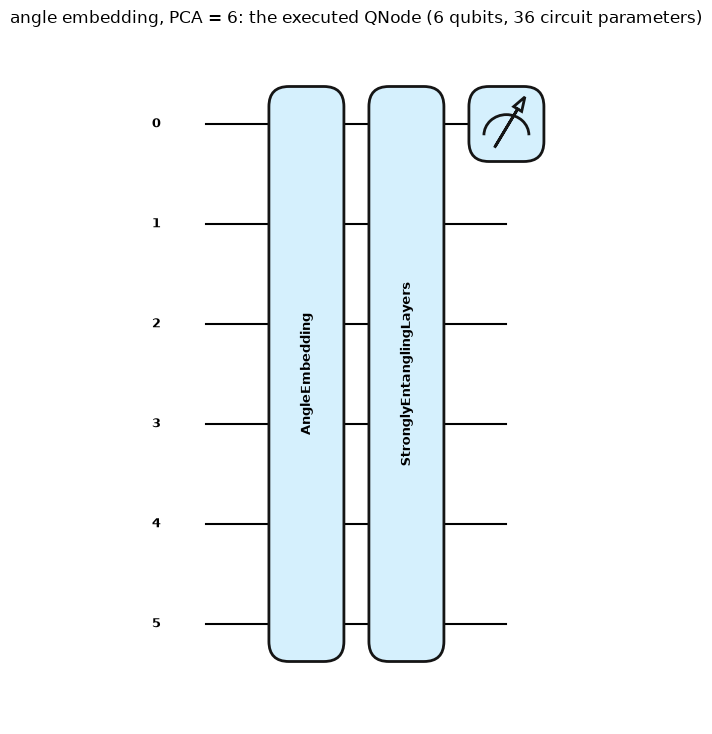

===== amplitude embedding, PCA = 8, 3 qubits =====
0: ─╭|Ψ⟩─╭StronglyEntanglingLayers(M0)─┤  <Z>
1: ─├|Ψ⟩─├StronglyEntanglingLayers(M0)─┤     
2: ─╰|Ψ⟩─╰StronglyEntanglingLayers(M0)─┤     


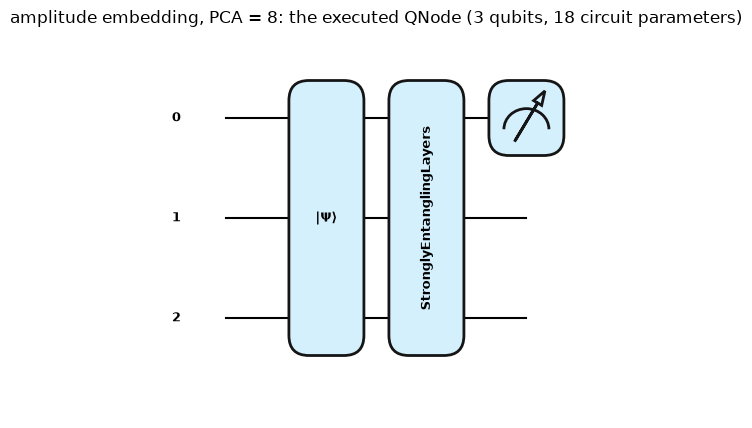

===== iqp embedding, PCA = 6, 6 qubits =====
0: ─╭IQPEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├IQPEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
2: ─├IQPEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
3: ─├IQPEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
4: ─├IQPEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤     
5: ─╰IQPEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤     


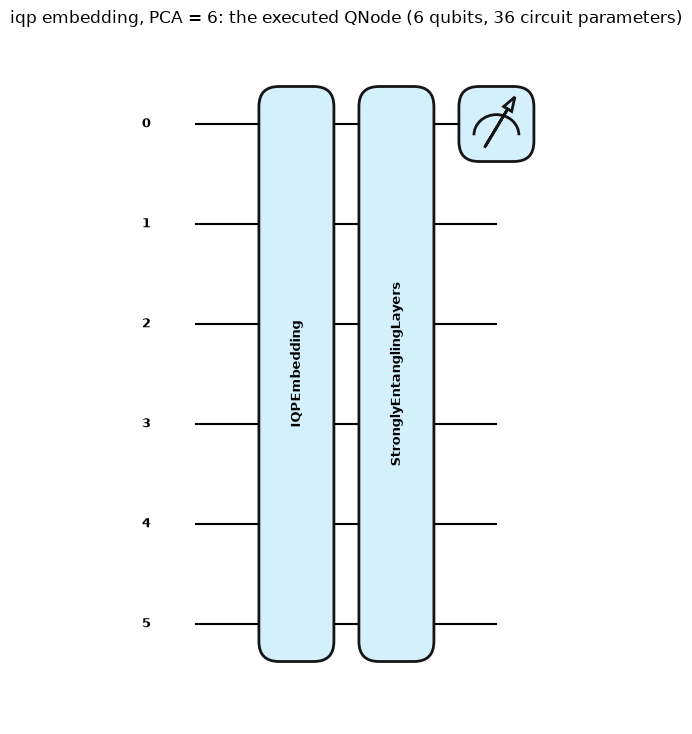

In [12]:
for (emb, k), m in ARCH.items():
    A = q_inputs(D0, emb, k)[0]
    x0 = torch.tensor(A[0], dtype=torch.float64)
    print(f"===== {emb} embedding, PCA = {k}, {m.nq} qubits =====")
    print(qml.draw(m.circuit, max_length=140, show_matrices=False)(x0, m.weights))
    fig, ax = qml.draw_mpl(m.circuit, decimals=2, style="pennylane", fontsize=9)(x0, m.weights)
    fig.suptitle(f"{emb} embedding, PCA = {k}: the executed QNode ({m.nq} qubits, {m.n_circuit_params()} circuit parameters)", y=1.02)
    plt.show()

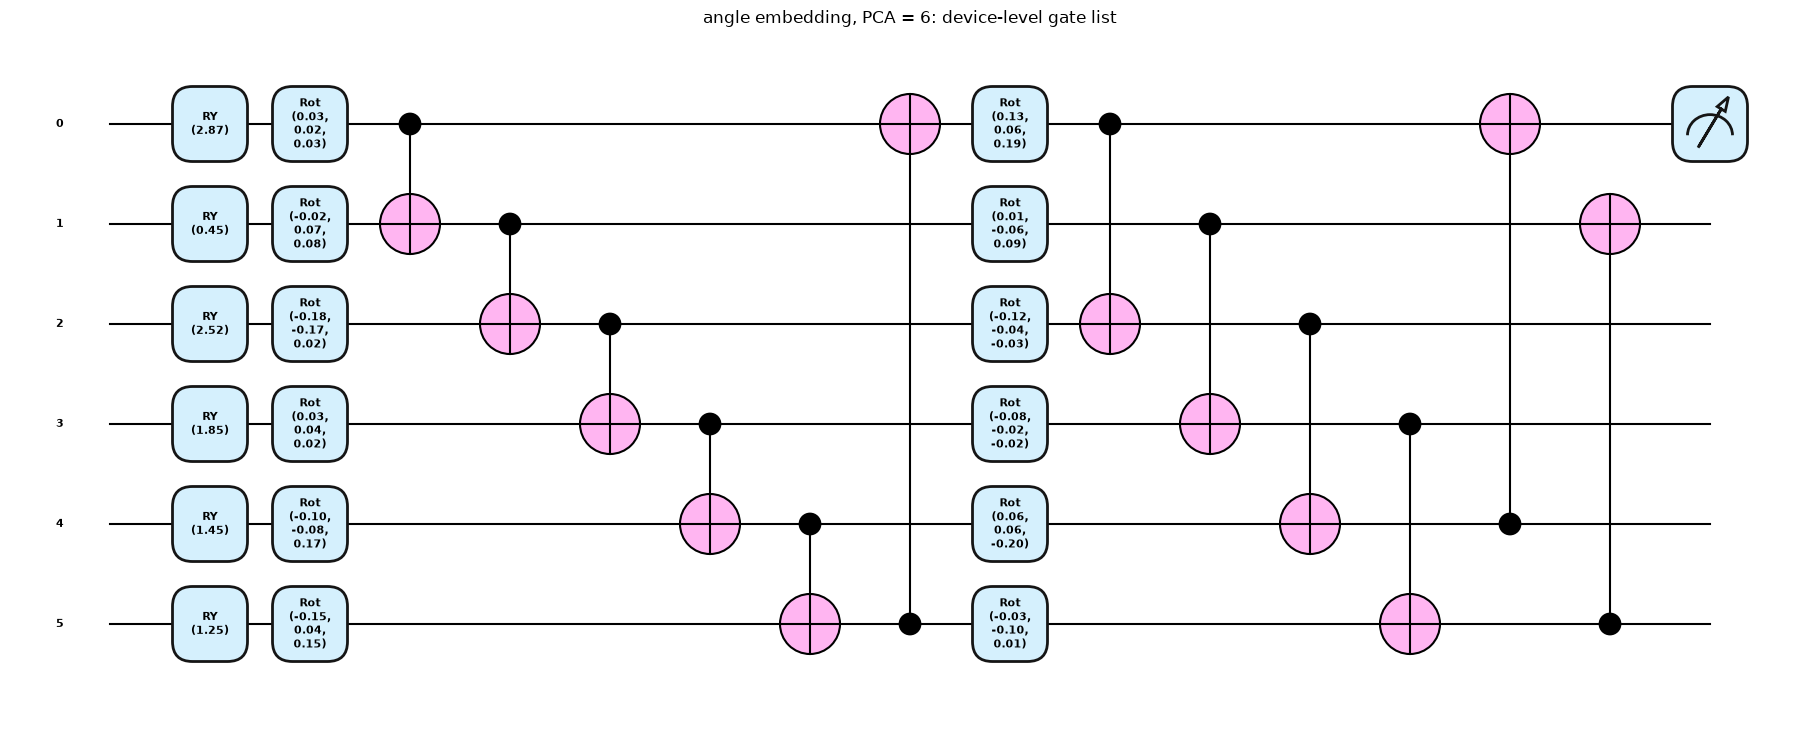

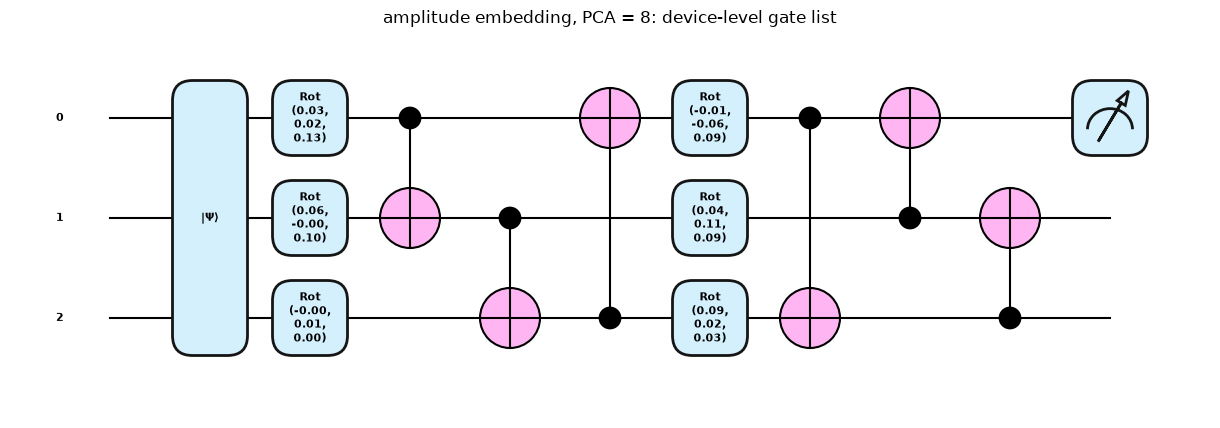

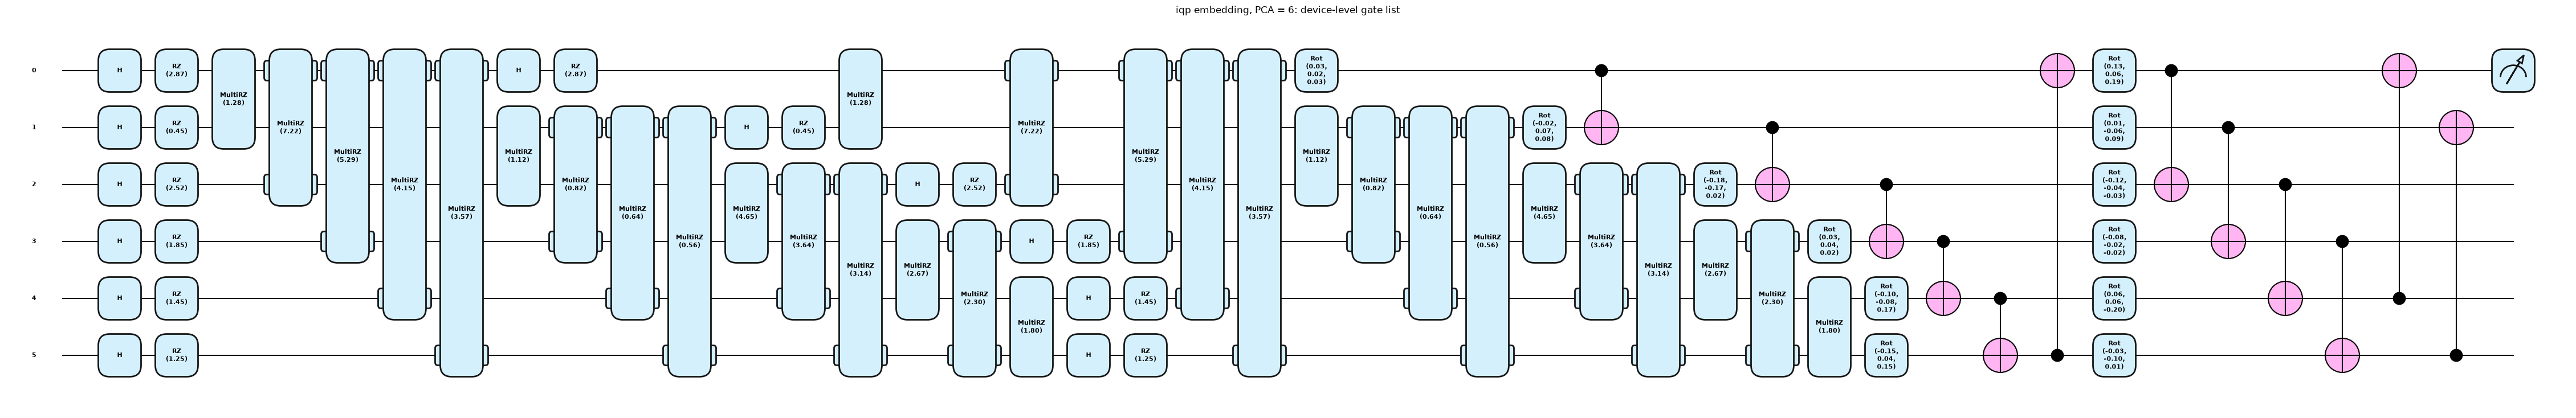

In [13]:
# Decomposed into the gates the simulator actually applies (device level). default.qubit loads the amplitude vector directly as
# one state-preparation operation (drawn as |Psi>; on hardware it would be compiled into a rotation/CNOT network); IQP becomes
# Hadamards, RZ and MultiRZ phases; StronglyEntanglingLayers becomes Rot gates and CNOTs.
for (emb, k), m in ARCH.items():
    A = q_inputs(D0, emb, k)[0]
    x0 = torch.tensor(A[0], dtype=torch.float64)
    fig, ax = qml.draw_mpl(m.circuit, level="device", decimals=2, style="pennylane", fontsize=8)(x0, m.weights)
    fig.suptitle(f"{emb} embedding, PCA = {k}: device-level gate list", y=1.02)
    plt.show()

In [14]:
# Equivalence check: the paper trains with the parameter-shift rule. Training here uses back-propagation through the simulator
# (identical gradient, far fewer circuit evaluations). Check it on 6 real training rows for every architecture.
for (emb, k), m in ARCH.items():
    A = torch.tensor(q_inputs(D0, emb, k)[0][:6], dtype=torch.float64)
    y6 = torch.tensor(D0["ytr"][:6], dtype=torch.float64)
    grads = {}
    for dm in ("backprop", "parameter-shift"):
        mm = HybridQNN(emb, k, LAYERS, SEED, diff_method=dm)
        loss = torch.nn.functional.binary_cross_entropy(mm(A), y6)
        loss.backward()
        grads[dm] = torch.cat([p.grad.flatten() for p in mm.parameters()]).numpy()
    ok = np.allclose(grads["backprop"], grads["parameter-shift"], atol=1e-8)
    print(f"{emb:10s} PCA={k}: max |grad_backprop - grad_parameter_shift| = {np.abs(grads['backprop'] - grads['parameter-shift']).max():.2e} -> equal: {ok}")
    assert ok

angle      PCA=6: max |grad_backprop - grad_parameter_shift| = 9.80e-17 -> equal: True


amplitude  PCA=8: max |grad_backprop - grad_parameter_shift| = 1.11e-16 -> equal: True


iqp        PCA=6: max |grad_backprop - grad_parameter_shift| = 8.46e-17 -> equal: True


## 4. Training the hybrid QNNs

Binary cross-entropy (paper Eq. 6) on mini-batches of 128 connections, Adam with a fixed learning rate of 0.05, a fixed
epoch budget (`EPOCHS`; the paper says "multiple epochs until convergence"). After every epoch the accuracy on the first
1,000 *training* rows is logged to draw the convergence curve. The test split is touched once, after training. Training
is repeated for every seed in `SEEDS`; each seed uses a different balanced draw, split and parameter initialisation.

In [15]:
def train_qnn(emb, k, layers, seed, label=None, epochs=None):
    epochs = epochs or EPOCHS
    d = DATA[seed]; Atr, Ate = q_inputs(d, emb, k)
    torch.manual_seed(seed)
    model = HybridQNN(emb, k, layers, seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    Xt = torch.tensor(Atr, dtype=torch.float64); Yt = torch.tensor(d["ytr"], dtype=torch.float64)
    g = torch.Generator().manual_seed(seed)
    hist = []; t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(Xt), generator=g); tot = 0.0
        for i in range(0, len(Xt), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 2: continue
            p = model(Xt[idx]).clamp(1e-7, 1 - 1e-7)
            loss = torch.nn.functional.binary_cross_entropy(p, Yt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        acc = float(((predict_proba(model, Atr[:PROBE]) > 0.5).astype(int) == d["ytr"][:PROBE]).mean())
        hist.append((tot / len(Xt), acc))
        if (ep + 1) % PRINT_EVERY == 0 or ep == 0 or ep + 1 == epochs:
            print(f"  {label or emb} seed {seed} epoch {ep + 1:2d}/{epochs}  loss {hist[-1][0]:.4f}  train-probe acc {acc:.4f}  ({time.time() - t0:.0f} s)", flush=True)
    train_s = time.time() - t0
    t1 = time.time(); proba = predict_proba(model, Ate); pred = (proba > 0.5).astype(int); pred_s = time.time() - t1
    out = dict(**binary_metrics(d["yte"], pred), time_s=train_s + pred_s, train_s=train_s, predict_s=pred_s,
               params=model.n_params(), circuit_params=model.n_circuit_params(), hist=hist, qubits=model.nq)
    return out, pred

QNN_NAME = {("angle", 6): "H-QNN Angle (PCA 6)", ("amplitude", 8): "H-QNN Amplitude (PCA 8)", ("iqp", 6): "H-QNN IQP (PCA 6)"}
t_all = time.time()
for s in SEEDS:
    for (emb, k) in MAIN_MODELS:
        name = QNN_NAME[(emb, k)]
        r, pred = train_qnn(emb, k, LAYERS, s, label=name)
        RES[(name, s)] = r; PRED[(name, s)] = pred
        print(f"{name}, seed {s}: test accuracy {r['accuracy']:.4f}, F1 {r['f1']:.4f}, train+predict {r['time_s']:.0f} s")
print("all main QNN runs: %.1f min" % ((time.time() - t_all) / 60))

  H-QNN Angle (PCA 6) seed 42 epoch  1/10  loss 0.2967  train-probe acc 0.9500  (40 s)


  H-QNN Angle (PCA 6) seed 42 epoch  3/10  loss 0.1478  train-probe acc 0.9640  (119 s)


  H-QNN Angle (PCA 6) seed 42 epoch  6/10  loss 0.1363  train-probe acc 0.9590  (252 s)


  H-QNN Angle (PCA 6) seed 42 epoch  9/10  loss 0.1371  train-probe acc 0.9560  (406 s)


  H-QNN Angle (PCA 6) seed 42 epoch 10/10  loss 0.1382  train-probe acc 0.9580  (451 s)


...

  H-QNN IQP (PCA 6) seed 44 epoch  3/10  loss 0.2019  train-probe acc 0.9390  (484 s)


  H-QNN IQP (PCA 6) seed 44 epoch  6/10  loss 0.1842  train-probe acc 0.9440  (947 s)


  H-QNN IQP (PCA 6) seed 44 epoch  9/10  loss 0.1824  train-probe acc 0.9460  (1388 s)


  H-QNN IQP (PCA 6) seed 44 epoch 10/10  loss 0.1821  train-probe acc 0.9430  (1500 s)


H-QNN IQP (PCA 6), seed 44: test accuracy 0.9349, F1 0.9353, train+predict 1506 s
all main QNN runs: 90.3 min


## 5. Results: Table I, convergence and confusion matrices

In [16]:
def summary(keys, seeds=SEEDS):
    rows = []
    for key in keys:
        r = [RES[(key, s)] for s in seeds]
        row = {"model": key}
        for m in ["accuracy", "precision", "recall", "f1", "fnr", "fpr"]:
            v = np.array([x[m] for x in r]); row[m] = f"{v.mean():.4f} +- {v.std():.4f}" if len(v) > 1 else f"{v.mean():.4f}"
        row["time_s (mean)"] = round(float(np.mean([x["time_s"] for x in r])), 1)
        row["params"] = r[0]["params"]
        rows.append(row)
    return pd.DataFrame(rows)

main_keys = list(QNN_NAME.values())
cl_keys = [f"{n} [{t}]" for t in ["PCA6 angles", "PCA8 scores", "all features"] for n in ["SVM (RBF)", "Random Forest", "Logistic Regression", "MLP (32-16)"]]
print(f"Test-set results, mean +- std over seeds {SEEDS} (attack = positive class; fnr = missed attacks, fpr = false alarms)")
display(summary(main_keys + cl_keys))

Test-set results, mean +- std over seeds [42, 43, 44] (attack = positive class; fnr = missed attacks, fpr = false alarms)


,model,accuracy,precision,recall,f1,fnr,fpr,time_s (mean),params
0,H-QNN Angle (PCA 6),0.9559 +- 0.0071,0.9750 +- 0.0068,0.9360 +- 0.0196,0.9549 +- 0.0079,0.0640 +- 0.0196,0.0241 +- 0.0070,673.0,38
1,H-QNN Amplitude (PCA 8),0.9547 +- 0.0046,0.9601 +- 0.0029,0.9488 +- 0.0125,0.9544 +- 0.0050,0.0512 +- 0.0125,0.0394 +- 0.0035,100.3,20
2,H-QNN IQP (PCA 6),0.9347 +- 0.0022,0.9348 +- 0.0109,0.9347 +- 0.0083,0.9347 +- 0.0016,0.0653 +- 0.0083,0.0654 +- 0.0121,1029.1,38
3,SVM (RBF) [PCA6 angles],0.9706 +- 0.0010,0.9882 +- 0.0034,0.9525 +- 0.0028,0.9700 +- 0.0010,0.0475 +- 0.0028,0.0114 +- 0.0033,4.5,1374
4,Random Forest [PCA6 angles],0.9899 +- 0.0014,0.9927 +- 0.0019,0.9869 +- 0.0045,0.9898 +- 0.0014,0.0131 +- 0.0045,0.0072 +- 0.0019,4.7,46724
5,Logistic Regression [PCA6 angles],0.9322 +- 0.0024,0.9383 +- 0.0055,0.9254 +- 0.0051,0.9318 +- 0.0023,0.0746 +- 0.0051,0.0609 +- 0.0060,0.1,7
6,MLP (32-16) [PCA6 angles],0.9796 +- 0.0013,0.9864 +- 0.0056,0.9728 +- 0.0079,0.9795 +- 0.0014,0.0272 +- 0.0079,0.0135 +- 0.0057,37.2,769
7,SVM (RBF) [PCA8 scores],0.9718 +- 0.0007,0.9901 +- 0.0034,0.9530 +- 0.0026,0.9712 +- 0.0007,0.0470 +- 0.0026,0.0095 +- 0.0033,4.3,1265
8,Random Forest [PCA8 scores],0.9906 +- 0.0012,0.9937 +- 0.0024,0.9875 +- 0.0048,0.9906 +- 0.0012,0.0125 +- 0.0048,0.0062 +- 0.0025,5.1,46638
9,Logistic Regression [PCA8 scores],0.9605 +- 0.0019,0.9641 +- 0.0044,0.9566 +- 0.0013,0.9603 +- 0.0018,0.0434 +- 0.0013,0.0356 +- 0.0046,0.0,9


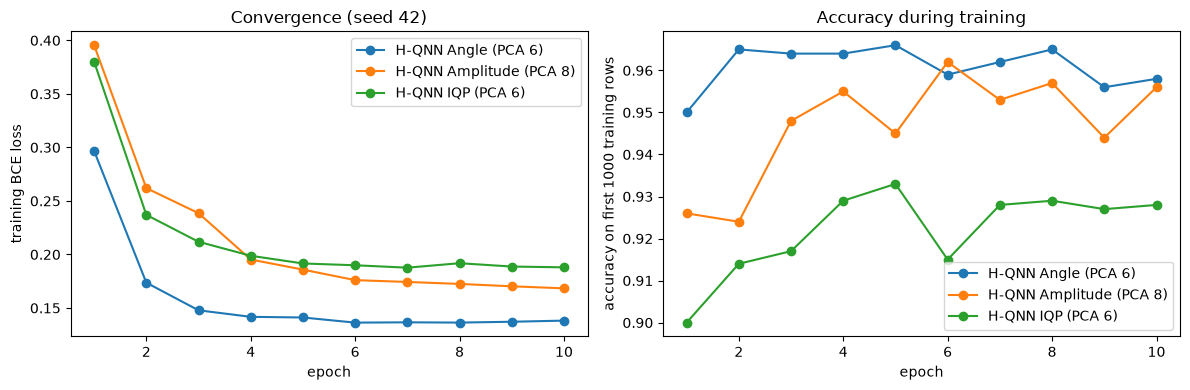

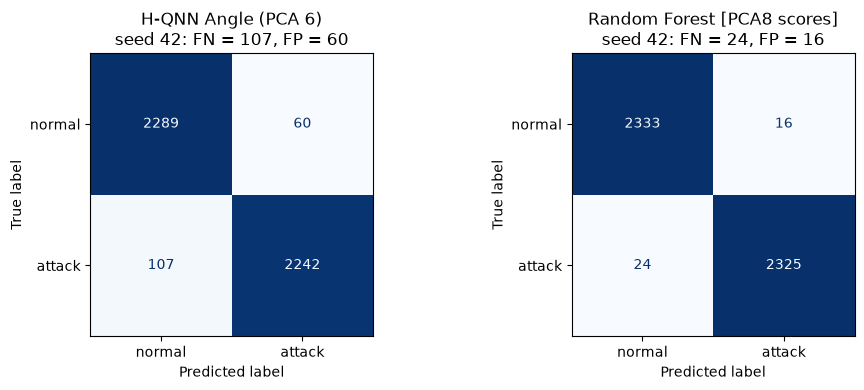

best H-QNN by mean accuracy: H-QNN Angle (PCA 6)


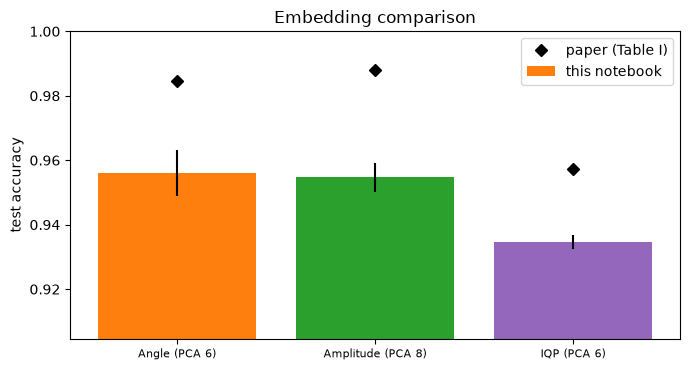

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (emb, k), name in QNN_NAME.items():
    h = np.array(RES[(name, SEEDS[0])]["hist"])
    axes[0].plot(range(1, len(h) + 1), h[:, 0], "o-", label=name); axes[1].plot(range(1, len(h) + 1), h[:, 1], "o-", label=name)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training BCE loss"); axes[0].set_title(f"Convergence (seed {SEEDS[0]})"); axes[0].legend()
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy on first %d training rows" % PROBE); axes[1].set_title("Accuracy during training"); axes[1].legend()
plt.tight_layout(); plt.show()

# Fig. 4 of the paper: confusion matrices of the best H-QNN and of the strongest classical baseline (seed 0 of SEEDS)
s0 = SEEDS[0]
best_q = max(main_keys, key=lambda n: np.mean([RES[(n, s)]["accuracy"] for s in SEEDS]))
rf_key = "Random Forest [PCA8 scores]"
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key in zip(axes, [best_q, rf_key]):
    ConfusionMatrixDisplay.from_predictions(DATA[s0]["yte"], PRED[(key, s0)], display_labels=["normal", "attack"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{key}\nseed {s0}: FN = {RES[(key, s0)]['fn']}, FP = {RES[(key, s0)]['fp']}")
plt.tight_layout(); plt.show()
print("best H-QNN by mean accuracy:", best_q)

# Impact of the embedding (paper Sec. V.3)
fig, ax = plt.subplots(figsize=(7, 3.8))
vals = [np.mean([RES[(n, s)]["accuracy"] for s in SEEDS]) for n in main_keys]
errs = [np.std([RES[(n, s)]["accuracy"] for s in SEEDS]) for n in main_keys]
ax.bar([n.replace("H-QNN ", "") for n in main_keys], vals, yerr=errs, color=["tab:orange", "tab:green", "tab:purple"], label="this notebook")
ax.plot([0, 1, 2], [0.9845, 0.9881, 0.9572], "kD", label="paper (Table I)")
ax.set_ylim(min(vals + [0.9572]) - 0.03, 1.0); ax.set_ylabel("test accuracy"); ax.legend(); ax.set_title("Embedding comparison")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

## 6. Ablation: PCA size and circuit depth

The paper runs an "ablation-oriented analysis" of the number of PCA components and of the embedding but reports no
numbers beyond Table I. We add a small grid with the first seed only: other PCA sizes for each embedding (as far as
`ABLATION_PCA` allows in this mode) and, for the amplitude model, 1, 4 and 7 variational layers (7 layers on 3 qubits is
63 circuit parameters, the closest match to the paper's "approximately 64"). The Random Forest column gives the classical
reference on the same PCA scores.

In [18]:
abl_rows = []
s0 = SEEDS[0]; t_abl = time.time()
for emb, ks in ABLATION_PCA.items():
    for k in ks:
        r, pred = train_qnn(emb, k, LAYERS, s0, label=f"ablation {emb} k={k}")
        rf = RandomForestClassifier(n_estimators=100, random_state=s0, n_jobs=1).fit(q_inputs(DATA[s0], emb, k)[0], DATA[s0]["ytr"])
        rf_acc = accuracy_score(DATA[s0]["yte"], rf.predict(q_inputs(DATA[s0], emb, k)[1]))
        abl_rows.append(dict(embedding=emb, pca=k, qubits=r["qubits"], layers=LAYERS, circuit_params=r["circuit_params"],
                             accuracy=r["accuracy"], f1=r["f1"], rf_accuracy=rf_acc, time_s=round(r["time_s"], 1)))
for L in ABLATION_LAYERS:
    r, pred = train_qnn("amplitude", 8, L, s0, label=f"ablation amplitude layers={L}")
    abl_rows.append(dict(embedding="amplitude", pca=8, qubits=r["qubits"], layers=L, circuit_params=r["circuit_params"],
                         accuracy=r["accuracy"], f1=r["f1"], rf_accuracy=RES[("Random Forest [PCA8 scores]", s0)]["accuracy"], time_s=round(r["time_s"], 1)))
# the main configurations (2 layers) for reference
for (emb, k), name in QNN_NAME.items():
    r = RES[(name, s0)]
    abl_rows.append(dict(embedding=emb, pca=k, qubits=r["qubits"], layers=LAYERS, circuit_params=r["circuit_params"], accuracy=r["accuracy"],
                         f1=r["f1"], rf_accuracy=RES[({"angle": "Random Forest [PCA6 angles]", "iqp": "Random Forest [PCA6 angles]", "amplitude": "Random Forest [PCA8 scores]"}[emb], s0)]["accuracy"],
                         time_s=round(r["time_s"], 1)))
ABL = pd.DataFrame(abl_rows).sort_values(["embedding", "pca", "layers"]).reset_index(drop=True)
print("ablation finished in %.1f min (seed %d)" % ((time.time() - t_abl) / 60, s0))
display(ABL.round(4))

  ablation angle k=4 seed 42 epoch  1/10  loss 0.3416  train-probe acc 0.9250  (36 s)


  ablation angle k=4 seed 42 epoch  3/10  loss 0.1951  train-probe acc 0.9250  (117 s)


  ablation angle k=4 seed 42 epoch  6/10  loss 0.1809  train-probe acc 0.9340  (231 s)


  ablation angle k=4 seed 42 epoch  9/10  loss 0.1821  train-probe acc 0.9360  (337 s)


  ablation angle k=4 seed 42 epoch 10/10  loss 0.1786  train-probe acc 0.9360  (369 s)


...

  ablation amplitude layers=7 seed 42 epoch  6/10  loss 0.1347  train-probe acc 0.9520  (315 s)


  ablation amplitude layers=7 seed 42 epoch  9/10  loss 0.1326  train-probe acc 0.9550  (505 s)


  ablation amplitude layers=7 seed 42 epoch 10/10  loss 0.1371  train-probe acc 0.9590  (563 s)


ablation finished in 26.1 min (seed 42)


,embedding,pca,qubits,layers,circuit_params,accuracy,f1,rf_accuracy,time_s
0,amplitude,4,2,2,12,0.8768,0.8758,0.9842,129.4
1,amplitude,8,3,1,9,0.7322,0.7652,0.9915,70.5
2,amplitude,8,3,2,18,0.9593,0.9595,0.9915,50.1
3,amplitude,8,3,4,36,0.9606,0.9609,0.9915,190.4
4,amplitude,8,3,7,63,0.9642,0.9644,0.9915,564.6
5,amplitude,16,4,2,24,0.9236,0.9227,0.9919,179.5
6,angle,4,4,2,24,0.9336,0.9338,0.9842,369.7
7,angle,6,6,2,36,0.9645,0.9641,0.9908,451.7
8,iqp,6,6,2,36,0.9319,0.9324,0.9908,805.2


## 7. Side by side with the paper

Verdict rule: a numeric claim is *reproduced* when the notebook's mean is within 0.02 of the paper's value (accuracy or F1),
otherwise *not reached* (we are lower) or *exceeded* (we are higher) with the gap shown. Qualitative claims are checked on
the means over `SEEDS`. Paper baselines are compared with the baselines trained on the PCA = 8 scores (the inputs of the
paper's best model). Times are not comparable in absolute terms (different hardware, unknown epoch counts) and are only
checked for the order of magnitude and the ranking.

In [19]:
def mean(key, m): return float(np.mean([RES[(key, s)][m] for s in SEEDS]))
def numeric_verdict(paper, ours, tol=0.02):
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached"), gap

claims = []
paper_table = [("H-QNN Angle (PCA 6)", 0.9845, 0.9830), ("H-QNN Amplitude (PCA 8)", 0.9881, 0.9875), ("H-QNN IQP (PCA 6)", 0.9572, 0.9550),
               ("SVM (RBF) [PCA8 scores]", 0.963, 0.961), ("Random Forest [PCA8 scores]", 0.972, 0.970), ("Logistic Regression [PCA8 scores]", 0.948, 0.945)]
for key, pa, pf in paper_table:
    for metric, pv in [("accuracy", pa), ("f1", pf)]:
        v, gap = numeric_verdict(pv, mean(key, metric))
        claims.append(dict(claim=f"{key}: {metric}", paper=pv, notebook=round(mean(key, metric), 4), gap=round(gap, 4), verdict=v))

# qualitative claims
q = {n: mean(n, "accuracy") for n in main_keys}
best_classical = max(cl_keys, key=lambda n: mean(n, "accuracy"))
rf_pca8_acc = mean("Random Forest [PCA8 scores]", "accuracy")
claims += [
    dict(claim="Amplitude H-QNN is the best of the three H-QNNs", paper="yes", notebook=max(q, key=q.get), gap="",
         verdict="reproduced" if max(q, key=q.get) == "H-QNN Amplitude (PCA 8)" else "not reached"),
    dict(claim="Amplitude H-QNN >= Random Forest on the same PCA scores", paper="0.9881 vs 0.972",
         notebook=f"{q['H-QNN Amplitude (PCA 8)']:.4f} vs {rf_pca8_acc:.4f}", gap=round(q["H-QNN Amplitude (PCA 8)"] - rf_pca8_acc, 4),
         verdict="reproduced" if q["H-QNN Amplitude (PCA 8)"] >= rf_pca8_acc else "not reached"),
    dict(claim="IQP is the weakest H-QNN", paper="yes", notebook=min(q, key=q.get), gap="",
         verdict="reproduced" if min(q, key=q.get) == "H-QNN IQP (PCA 6)" else "not reached"),
    dict(claim="Amplitude H-QNN has a lower false-negative rate than Random Forest", paper="yes (Fig. 4)",
         notebook=f"FNR {mean('H-QNN Amplitude (PCA 8)', 'fnr'):.4f} vs {mean('Random Forest [PCA8 scores]', 'fnr'):.4f}", gap="",
         verdict="reproduced" if mean("H-QNN Amplitude (PCA 8)", "fnr") < mean("Random Forest [PCA8 scores]", "fnr") else "not reached"),
    dict(claim="Amplitude H-QNN has about 64 trainable parameters (2 layers)", paper="~64",
         notebook=f"{RES[('H-QNN Amplitude (PCA 8)', SEEDS[0])]['circuit_params']} circuit (+2 head)", gap="",
         verdict="not reached (3 qubits x 2 layers x 3 angles = 18)"),
    dict(claim="Angle trains faster than amplitude (paper: 3010 s vs 4620 s)", paper="angle < amplitude",
         notebook=f"{mean('H-QNN Angle (PCA 6)', 'time_s'):.0f} s vs {mean('H-QNN Amplitude (PCA 8)', 'time_s'):.0f} s", gap="",
         verdict="reproduced" if mean("H-QNN Angle (PCA 6)", "time_s") < mean("H-QNN Amplitude (PCA 8)", "time_s") else "not reached"),
    dict(claim="H-QNN training is much slower than the classical baselines (paper: 3-15 s)", paper="100-1000x slower",
         notebook=f"{min(mean(n, 'time_s') for n in main_keys):.0f}-{max(mean(n, 'time_s') for n in main_keys):.0f} s vs {mean('Random Forest [PCA8 scores]', 'time_s'):.1f} s (RF)", gap="",
         verdict="reproduced" if min(mean(n, 'time_s') for n in main_keys) > 10 * mean("Random Forest [PCA8 scores]", "time_s") else "not reached"),
    dict(claim="Amplitude H-QNN is parameter-efficient vs an MLP with comparable accuracy", paper="64 vs several thousand",
         notebook=f"{RES[('H-QNN Amplitude (PCA 8)', SEEDS[0])]['params']} params vs MLP {RES[('MLP (32-16) [PCA8 scores]', SEEDS[0])]['params']} (acc {mean('MLP (32-16) [PCA8 scores]', 'accuracy'):.4f})",
         gap="", verdict="see text: the parameter count is small but the accuracy is "
                         + ("comparable" if abs(q["H-QNN Amplitude (PCA 8)"] - mean("MLP (32-16) [PCA8 scores]", "accuracy")) < 0.01 else "lower than the MLP's")),
    dict(claim="Hybrid QNNs beat the strongest classical model", paper="98.81% vs 97.2%",
         notebook=f"best H-QNN {max(q.values()):.4f} vs best classical on same PCA inputs {max(mean(n, 'accuracy') for n in cl_keys if 'all features' not in n):.4f}", gap="",
         verdict="reproduced" if max(q.values()) > max(mean(n, 'accuracy') for n in cl_keys if 'all features' not in n) else "not reached"),
]
CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 90)
display(CLAIMS)
print(CLAIMS["verdict"].map(lambda v: "not reached" if v.startswith("not reached") else ("reproduced" if v.startswith("reproduced") else ("exceeded" if v.startswith("exceeded") else "see text"))).value_counts().to_string())

,claim,paper,notebook,gap,verdict
0,H-QNN Angle (PCA 6): accuracy,0.9845,0.9559,-0.0286,not reached
1,H-QNN Angle (PCA 6): f1,0.983,0.9549,-0.0281,not reached
2,H-QNN Amplitude (PCA 8): accuracy,0.9881,0.9547,-0.0334,not reached
3,H-QNN Amplitude (PCA 8): f1,0.9875,0.9544,-0.0331,not reached
4,H-QNN IQP (PCA 6): accuracy,0.9572,0.9347,-0.0225,not reached
5,H-QNN IQP (PCA 6): f1,0.955,0.9347,-0.0203,not reached
6,SVM (RBF) [PCA8 scores]: accuracy,0.963,0.9718,0.0088,reproduced
7,SVM (RBF) [PCA8 scores]: f1,0.961,0.9712,0.0102,reproduced
8,Random Forest [PCA8 scores]: accuracy,0.972,0.9906,0.0186,reproduced
9,Random Forest [PCA8 scores]: f1,0.97,0.9906,0.0206,exceeded


verdict
not reached    12
reproduced      7
exceeded        1
see text        1


## 8. Reading the paper critically
CRIT TBD

## 9. Exercises
EXER TBD